In [10]:
%load_ext autoreload
%autoreload 2   

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning) 

In [12]:
import sys
from pathlib import Path

root = Path.cwd().parent
sys.path.insert(0, str(root))

from collections import OrderedDict
from pathlib import Path

import representation_spaces as rs
from data import GoEmotions
import part1
import torch


## Data statistics

#TODO: write dataset description

#TODO: how to handle multi-class data points?

#TODO: merge dev and train for cross-validation?

In [13]:
ds = GoEmotions(drop_multi_labels=True)
ds.summary

,Total comments,Average n tokens,Median n tokens,Max tokens
train,36308.0,15.37,15.0,47.0
dev,4548.0,15.29,15.0,37.0
test,4590.0,15.26,15.0,37.0


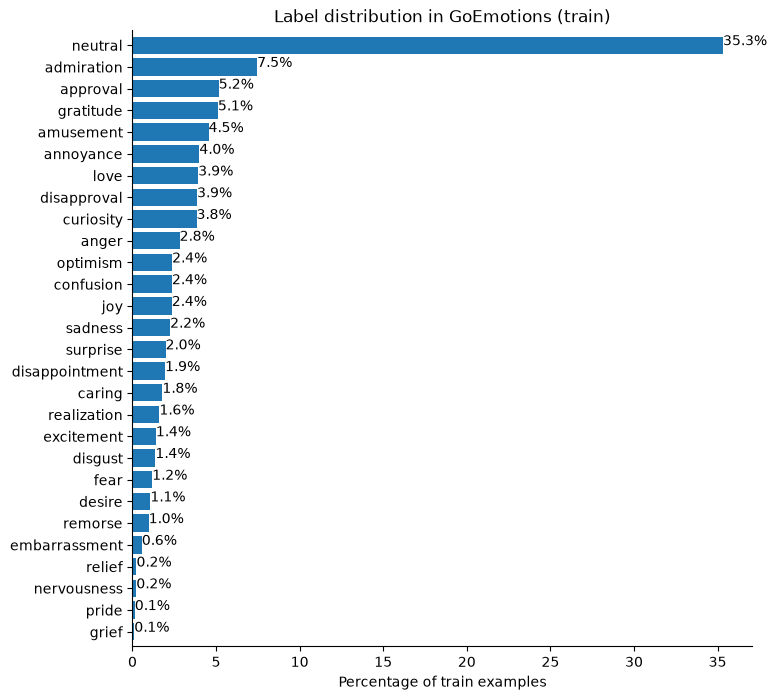

In [14]:
ds.plot_label_dist()

## Experiment

#TODO: description

In [15]:
from tokenizer import WordTokenizer

vocab_size = None
min_frequency = 1
tokenizer = WordTokenizer().train(ds.train["text"].tolist(), vocab_size=None, min_frequency=min_frequency)
token_indicator_encoder = rs.TokenIndicator(tokenizer)

# bag_of_words_encoder = rs.BagOfWords(tokenizer)

my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []

for seed in my_seeds:
    my_cross_validation_sets.append(
        part1.experiment.cross_validation_split(
            pairs=list(zip(ds.train["text"], ds.train["label"])), 
            k=num_folds,
            seed=seed)
    )

results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True)

emotions_outcome_space = part1.clslib.NamedClasses(names=ds.emotions)

In [16]:
tokenizer.save(f"{results_folder}/word_tokenizer_vs_{len(tokenizer.get_vocab())}_mf_{min_frequency}.json")

In [17]:
configs = {
    'deeper_mlp_indicator-enc': {
        'encoder': token_indicator_encoder,
        'model_option': 'mlp',
        'extra_args':{
            'smlp_args': {
                'hidden_dim': 128, 
                'num_hidden_layers': 2,
                'dropout': 0.1, 
                'batch_size': 512, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 10,
                'device': 'cuda' if torch.cuda.is_available() else 'cpu',
            }
        }
    },
    'logistic_indicator-enc': {
        'encoder': token_indicator_encoder,
        'model_option': 'logistic',
        'extra_args':{
            'loglin_args': {
                'max_iter': 300,
            }
        }
    },
    'mlp_indicator-enc': {
        'encoder': token_indicator_encoder,
        'model_option': 'mlp',
        'extra_args':{
            'smlp_args': {
                'hidden_dim': 128, 
                'num_hidden_layers': 1,
                'dropout': 0.1, 
                'batch_size': 512, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 10,
                'device': 'cuda' if torch.cuda.is_available() else 'cpu',
            }
        }
    },
}

my_classifiers = OrderedDict()
for config in configs:
    my_classifiers[config] = []
    for run, seed in enumerate(my_seeds):
        run_folder = f"{results_folder}/{config}/seed-{seed}"
        my_classifiers[config].append(
            part1.experiment.cross_validation_experiment(
                data_splits=my_cross_validation_sets[run],
                outcome_space=emotions_outcome_space,
                encoder=configs[config]['encoder'],
                model_option=configs[config]['model_option'],
                save_to=run_folder,
                **configs[config]['extra_args'],
            )
        )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 39.178 seconds
Dataloader done! Time taken: 1.580 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 2.8485 | train acc: 0.3348 | val loss: 2.6065 | val acc: 0.3524
Epoch 02 | train loss: 2.4423 | train acc: 0.3625 | val loss: 2.3026 | val acc: 0.3907
Epoch 03 | train loss: 1.9998 | train acc: 0.4615 | val loss: 1.9351 | val acc: 0.4957
Epoch 04 | train loss: 1.6382 | train acc: 0.5387 | val loss: 1.8098 | val acc: 0.5202
Epoch 05 | train loss: 1.3734 | train acc: 0.6044 | val loss: 1.7592 | val acc: 0.5366
Epoch 06 | train loss: 1.1546 | train acc: 0.6614 | val loss: 1.7650 | val acc: 0.5416
Epoch 07 | train loss: 0.9736 | train acc: 0.7135 | val loss: 1.8144 | val acc: 0.5375
Epoch 08 | train loss: 0.8271 | train acc: 0.7585 | val loss: 1.9001 | val acc: 0.5350
Epoch 09 | train loss: 0.6946 | train acc: 0.7970 | val loss: 1.9884 | val acc: 0.5328
Epoch 10 | train loss: 0.5860 | train acc: 0.8300 | val loss: 2.0798 | val acc: 0.5182
Training done! Time taken: 11.091 seconds
Transforming documents...
Document transformation done! Time taken: 38.370 seconds
Datal

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 2.8743 | train acc: 0.3161 | val loss: 2.6037 | val acc: 0.3543
Epoch 02 | train loss: 2.4288 | train acc: 0.3714 | val loss: 2.2562 | val acc: 0.4204
Epoch 03 | train loss: 1.9771 | train acc: 0.4774 | val loss: 1.9577 | val acc: 0.4895
Epoch 04 | train loss: 1.6433 | train acc: 0.5407 | val loss: 1.8321 | val acc: 0.5107
Epoch 05 | train loss: 1.3736 | train acc: 0.6050 | val loss: 1.7760 | val acc: 0.5270
Epoch 06 | train loss: 1.1439 | train acc: 0.6676 | val loss: 1.7936 | val acc: 0.5369
Epoch 07 | train loss: 0.9623 | train acc: 0.7191 | val loss: 1.8419 | val acc: 0.5278
Epoch 08 | train loss: 0.8144 | train acc: 0.7616 | val loss: 1.9135 | val acc: 0.5242
Epoch 09 | train loss: 0.6900 | train acc: 0.7989 | val loss: 2.0293 | val acc: 0.5224
Epoch 10 | train loss: 0.5831 | train acc: 0.8315 | val loss: 2.1125 | val acc: 0.5178
Training done! Time taken: 11.427 seconds
Transforming documents...
Document transformation done! Time taken: 40.760 seconds
Datal

... (15 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 2.9082 | train acc: 0.3071 | val loss: 2.6104 | val acc: 0.3776
Epoch 02 | train loss: 2.4428 | train acc: 0.4034 | val loss: 2.2765 | val acc: 0.4510
Epoch 03 | train loss: 2.0131 | train acc: 0.4865 | val loss: 1.9615 | val acc: 0.5003
Epoch 04 | train loss: 1.6439 | train acc: 0.5546 | val loss: 1.7707 | val acc: 0.5280
Epoch 05 | train loss: 1.3801 | train acc: 0.6127 | val loss: 1.6737 | val acc: 0.5446
Epoch 06 | train loss: 1.1909 | train acc: 0.6584 | val loss: 1.6347 | val acc: 0.5532
Epoch 07 | train loss: 1.0560 | train acc: 0.6916 | val loss: 1.6218 | val acc: 0.5462
Epoch 08 | train loss: 0.9489 | train acc: 0.7195 | val loss: 1.6330 | val acc: 0.5483
Epoch 09 | train loss: 0.8580 | train acc: 0.7439 | val loss: 1.6482 | val acc: 0.5459
Epoch 10 | train loss: 0.7840 | train acc: 0.7663 | val loss: 1.6807 | val acc: 0.5461
Training done! Time taken: 10.511 seconds
Transforming documents...
Document transformation done! Time taken: 39.095 seconds
Datal

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 2.8943 | train acc: 0.3325 | val loss: 2.6267 | val acc: 0.3643
Epoch 02 | train loss: 2.4317 | train acc: 0.4081 | val loss: 2.2897 | val acc: 0.4417
Epoch 03 | train loss: 2.0039 | train acc: 0.4929 | val loss: 1.9812 | val acc: 0.4940
Epoch 04 | train loss: 1.6392 | train acc: 0.5551 | val loss: 1.7918 | val acc: 0.5182
Epoch 05 | train loss: 1.3756 | train acc: 0.6124 | val loss: 1.6940 | val acc: 0.5315
Epoch 06 | train loss: 1.1905 | train acc: 0.6565 | val loss: 1.6497 | val acc: 0.5455
Epoch 07 | train loss: 1.0551 | train acc: 0.6903 | val loss: 1.6376 | val acc: 0.5479
Epoch 08 | train loss: 0.9442 | train acc: 0.7226 | val loss: 1.6512 | val acc: 0.5435
Epoch 09 | train loss: 0.8612 | train acc: 0.7441 | val loss: 1.6675 | val acc: 0.5463
Epoch 10 | train loss: 0.7865 | train acc: 0.7641 | val loss: 1.6995 | val acc: 0.5423
Training done! Time taken: 10.798 seconds


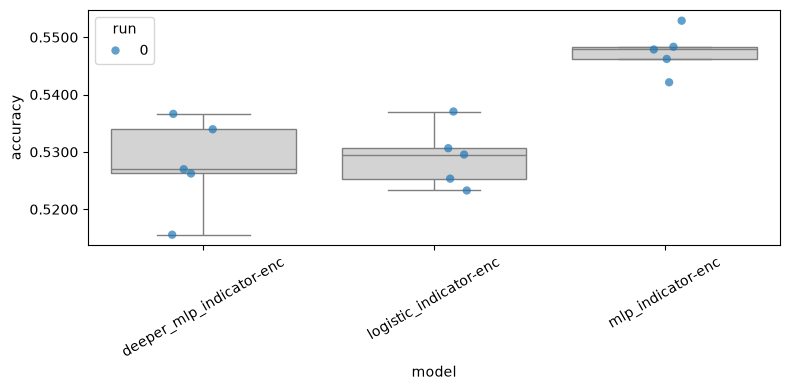

In [18]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))